In [ ]:
import os

# Create a fresh folder
DATA_DIR = "/content/sepsis_data"
os.makedirs(DATA_DIR, exist_ok=True)

print("Dataset folder ready:", DATA_DIR)

Dataset folder ready: /content/sepsis_data


In [ ]:
!pip -q install requests tqdm

In [ ]:
import requests

url = "https://physionet.org/files/challenge-2019/1.0.0/training/"

response = requests.get(url)

print("Status code:", response.status_code)
print(response.text[:5000])

Status code: 200
<html>
<head><title>Index of /protected/published-projects/challenge-2019/1.0.0/training/</title></head>
<body>
<h1>Index of /protected/published-projects/challenge-2019/1.0.0/training/</h1><hr><pre><a href="../">../</a>
<a href="training_setA/">training_setA/</a>                                     31-Mar-2019 20:56                   -
<a href="training_setB/">training_setB/</a>                                     01-Apr-2019 15:04                   -
</pre><hr></body>
</html>



In [ ]:
import requests

url = "https://physionet.org/files/challenge-2019/1.0.0/training/training_setA/"

response = requests.get(url)

print("Status code:", response.status_code)
print(response.text[:3000])

Status code: 200
<html>
<head><title>Index of /protected/published-projects/challenge-2019/1.0.0/training/training_setA/</title></head>
<body>
<h1>Index of /protected/published-projects/challenge-2019/1.0.0/training/training_setA/</h1><hr><pre><a href="../">../</a>
<a href="p000001.psv">p000001.psv</a>                                        27-Mar-2019 18:57                9062
<a href="p000002.psv">p000002.psv</a>                                        27-Mar-2019 18:57                3864
<a href="p000003.psv">p000003.psv</a>                                        27-Mar-2019 18:57                7928
<a href="p000004.psv">p000004.psv</a>                                        27-Mar-2019 18:57                4870
<a href="p000005.psv">p000005.psv</a>                                        27-Mar-2019 18:57                7850
<a href="p000006.psv">p000006.psv</a>                                        27-Mar-2019 18:57                2982
<a href="p000007.psv">p000007.psv</a>       

In [ ]:
import re

files = re.findall(
    r'href="([^"]+\.psv)"',
    response.text
)

print("Files listed:", len(files))
print("First 5 filenames:", files[:5])

Files listed: 20336
First 5 filenames: ['p000001.psv', 'p000002.psv', 'p000003.psv', 'p000004.psv', 'p000005.psv']


In [ ]:
!pip install -q tqdm requests

In [ ]:
import os
import re
import requests
from concurrent.futures import ThreadPoolExecutor
from tqdm.notebook import tqdm

# Main dataset folder
BASE_DIR = "/content/sepsis_data"

# Official PhysioNet URL
BASE_URL = "https://physionet.org/files/challenge-2019/1.0.0/training/"

# Create folders
os.makedirs(BASE_DIR, exist_ok=True)

# Download function
def download_patient(args):

    url, save_path = args

    # Skip already downloaded files
    if os.path.exists(save_path) and os.path.getsize(save_path) > 0:
        return True

    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()

        with open(save_path, "wb") as f:
            f.write(response.content)

        return True

    except Exception as e:
        return False


# Process both training sets
for set_name in ["training_setA", "training_setB"]:

    print(f"\nDownloading {set_name}...")

    folder_url = BASE_URL + set_name + "/"

    response = requests.get(folder_url, timeout=60)
    response.raise_for_status()

    # Extract patient filenames
    filenames = re.findall(
        r'href="(p\d+\.psv)"',
        response.text
    )

    print("Patient files found:", len(filenames))

    save_folder = os.path.join(BASE_DIR, set_name)
    os.makedirs(save_folder, exist_ok=True)

    # Prepare download tasks
    tasks = [
        (
            folder_url + filename,
            os.path.join(save_folder, filename)
        )
        for filename in filenames
    ]

    # Download using 12 parallel workers
    with ThreadPoolExecutor(max_workers=12) as executor:

        results = list(
            tqdm(
                executor.map(download_patient, tasks),
                total=len(tasks),
                desc=set_name
            )
        )

    print("Successfully downloaded:", sum(results))
    print("Failed downloads:", results.count(False))

print("\nDownload process completed!")


Patient files found: 20336


training_setA:   0%|          | 0/20336 [00:00<?, ?it/s]

Successfully downloaded: 20310
Failed downloads: 26

Patient files found: 20000


training_setB:   0%|          | 0/20000 [00:00<?, ?it/s]

Successfully downloaded: 19991
Failed downloads: 9

Download process completed!


In [ ]:
import glob
import os

for set_name in ["training_setA", "training_setB"]:

    folder = f"/content/sepsis_data/{set_name}"

    files = glob.glob(folder + "/*.psv")

    print(set_name, ":", len(files), "patient files")

all_files = glob.glob(
    "/content/sepsis_data/**/*.psv",
    recursive=True
)

print("\nTOTAL PATIENT FILES:", len(all_files))

training_setA : 20310 patient files
training_setB : 19991 patient files

TOTAL PATIENT FILES: 40301


In [ ]:
import requests
import os
import re
from concurrent.futures import ThreadPoolExecutor
from tqdm.notebook import tqdm

BASE_URL = "https://physionet.org/files/challenge-2019/1.0.0/training/"
BASE_DIR = "/content/sepsis_data"

def download_missing(args):
    url, path = args

    try:
        r = requests.get(url, timeout=60)
        r.raise_for_status()

        with open(path, "wb") as f:
            f.write(r.content)

        return True
    except Exception as e:
        return False

for set_name, expected_count in [
    ("training_setA", 20336),
    ("training_setB", 20000)
]:

    folder_url = BASE_URL + set_name + "/"
    save_folder = os.path.join(BASE_DIR, set_name)

    response = requests.get(folder_url)
    response.raise_for_status()

    filenames = re.findall(
        r'href="(p\d+\.psv)"',
        response.text
    )

    missing_tasks = []

    for filename in filenames:
        path = os.path.join(save_folder, filename)

        if not os.path.exists(path) or os.path.getsize(path) == 0:
            missing_tasks.append((folder_url + filename, path))

    print(set_name, "- Missing:", len(missing_tasks))

    with ThreadPoolExecutor(max_workers=8) as executor:
        results = list(tqdm(
            executor.map(download_missing, missing_tasks),
            total=len(missing_tasks)
        ))

    print("Successfully recovered:", sum(results))

training_setA - Missing: 26


  0%|          | 0/26 [00:00<?, ?it/s]

Successfully recovered: 26
training_setB - Missing: 9


  0%|          | 0/9 [00:00<?, ?it/s]

Successfully recovered: 9


In [ ]:
import glob
import os

for set_name in ["training_setA", "training_setB"]:

    files = glob.glob(
        f"/content/sepsis_data/{set_name}/*.psv"
    )

    print(set_name, ":", len(files))

all_files = glob.glob(
    "/content/sepsis_data/**/*.psv",
    recursive=True
)

print("\nTOTAL:", len(all_files))

training_setA : 20336
training_setB : 20000

TOTAL: 40336


In [ ]:
import pandas as pd
import glob
import os

all_files = glob.glob(
    "/content/sepsis_data/**/*.psv",
    recursive=True
)

dataframes = []

for file in all_files:

    df = pd.read_csv(file, sep="|")

    # Unique ID: training set + patient filename
    set_name = os.path.basename(os.path.dirname(file))
    patient_name = os.path.basename(file).replace(".psv", "")

    df["Patient_ID"] = set_name + "_" + patient_name

    dataframes.append(df)

data = pd.concat(dataframes, ignore_index=True)

print("Dataset shape:", data.shape)
print("\nNumber of unique patients:", data["Patient_ID"].nunique())

data.head()

Dataset shape: (1552210, 42)

Number of unique patients: 40336


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,22.15,0,NaN,NaN,-0.02,1,0,training_setA_p000150
1,103.0,100.0,NaN,125.0,95.0,NaN,25.0,NaN,NaN,NaN,...,NaN,NaN,22.15,0,NaN,NaN,-0.02,2,0,training_setA_p000150
2,94.0,100.0,35.83,126.0,105.0,NaN,14.0,NaN,NaN,NaN,...,NaN,NaN,22.15,0,NaN,NaN,-0.02,3,0,training_setA_p000150
3,96.0,100.0,NaN,108.0,81.0,NaN,13.0,NaN,NaN,25.0,...,NaN,210.0,22.15,0,NaN,NaN,-0.02,4,0,training_setA_p000150
4,100.0,100.0,35.94,113.0,83.0,NaN,15.0,NaN,NaN,NaN,...,NaN,NaN,22.15,0,NaN,NaN,-0.02,5,0,training_setA_p000150


**EDA**

In [ ]:
print("Column names:")
print(data.columns.tolist())

print("\nData types:")
print(data.dtypes)

print("\nDataset information:")
data.info()

Column names:
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID']

Data types:
HR                  float64
O2Sat               float64
Temp                float64
SBP                 float64
MAP                 float64
DBP                 float64
Resp                float64
EtCO2               float64
BaseExcess          float64
HCO3                float64
FiO2                float64
pH                  float64
PaCO2               float64
SaO2                float64
AST                 float64
BUN                 float64
Alkalinephos        float64
Calcium             float64
Chloride            float64
Cr

In [ ]:
# Calculate missing values
missing_values = data.isnull().sum()

# Calculate missing percentages
missing_percentage = (
    data.isnull().mean() * 100
).round(2)

# Create summary table
missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": missing_percentage
})

# Sort from highest to lowest missingness
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing_summary)

                  Missing_Count  Missing_Percentage
Bilirubin_direct        1549220               99.81
Fibrinogen              1541968               99.34
TroponinI               1537429               99.05
Bilirubin_total         1529069               98.51
Alkalinephos            1527269               98.39
AST                     1527027               98.38
Lactate                 1510764               97.33
PTT                     1506511               97.06
SaO2                    1498649               96.55
EtCO2                   1494574               96.29
Phosphate               1489909               95.99
HCO3                    1487182               95.81
Chloride                1481744               95.46
BaseExcess              1468065               94.58
PaCO2                   1465909               94.44
Calcium                 1460879               94.12
Platelets               1460001               94.06
Creatinine              1457594               93.90
Magnesium   

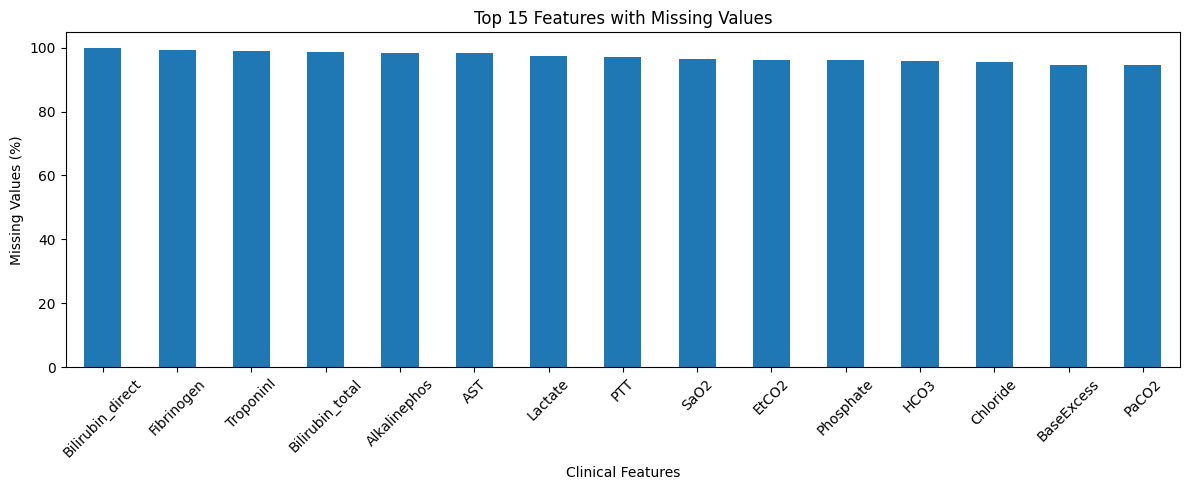

In [ ]:
import matplotlib.pyplot as plt

missing_summary.head(15)["Missing_Percentage"].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Top 15 Features with Missing Values")
plt.xlabel("Clinical Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**SepsisLabel Distribution**

In [ ]:
label_counts = data["SepsisLabel"].value_counts().sort_index()

print("Sepsis Label Counts:")
print(label_counts)

print("\nPercentage Distribution:")
print(
    data["SepsisLabel"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Sepsis Label Counts:
SepsisLabel
0    1524294
1      27916
Name: count, dtype: int64

Percentage Distribution:
SepsisLabel
0    98.2
1     1.8
Name: proportion, dtype: float64


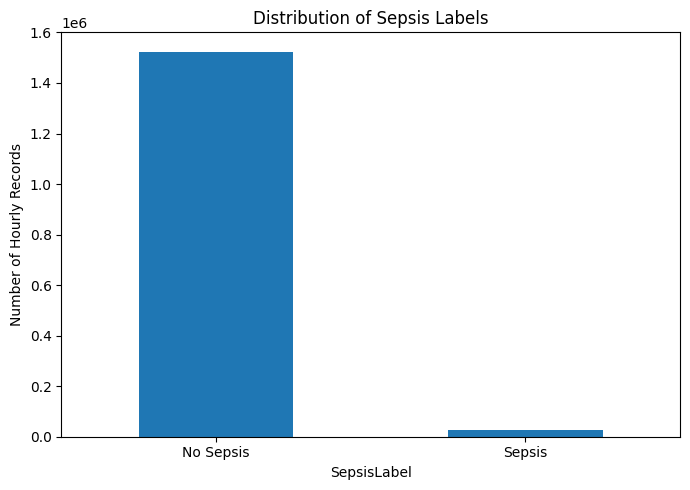

In [ ]:
label_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Distribution of Sepsis Labels")
plt.xlabel("SepsisLabel")
plt.ylabel("Number of Hourly Records")
plt.xticks([0, 1], ["No Sepsis", "Sepsis"], rotation=0)
plt.tight_layout()
plt.show()

**Patient Level Sepsis Distribution**

In [ ]:
patient_sepsis = (
    data.groupby("Patient_ID")["SepsisLabel"]
    .max()
)

patient_counts = patient_sepsis.value_counts().sort_index()

print("Patient-level Sepsis Distribution:")
print(patient_counts)

print("\nPercentage:")
print(
    patient_sepsis.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Patient-level Sepsis Distribution:
SepsisLabel
0    37404
1     2932
Name: count, dtype: int64

Percentage:
SepsisLabel
0    92.73
1     7.27
Name: proportion, dtype: float64


**ICU Stay Duration**

In [ ]:
patient_hours = data.groupby("Patient_ID")["ICULOS"].max()

print("ICU Stay Duration Statistics:")
print(patient_hours.describe())

ICU Stay Duration Statistics:
count    40336.000000
mean        39.010115
std         22.924641
min          8.000000
25%         24.000000
50%         39.000000
75%         47.000000
max        336.000000
Name: ICULOS, dtype: float64


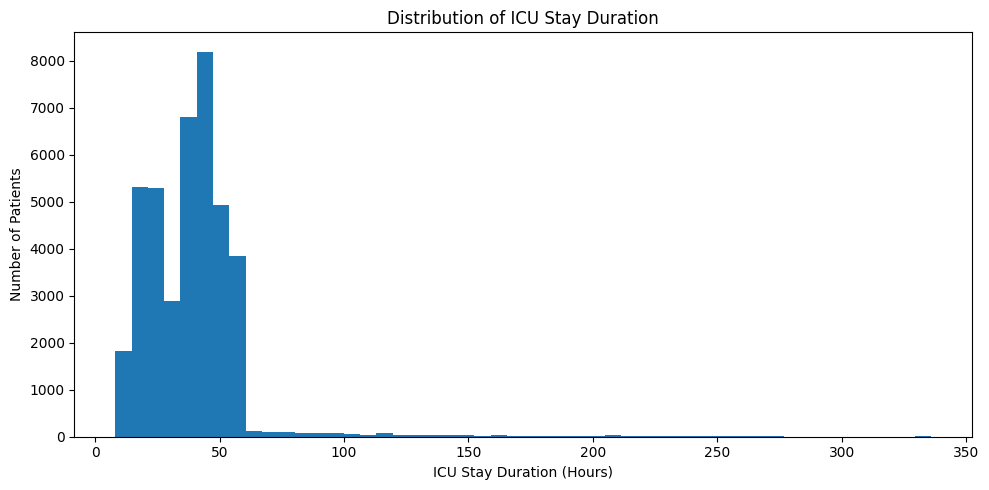

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(patient_hours, bins=50)

plt.title("Distribution of ICU Stay Duration")
plt.xlabel("ICU Stay Duration (Hours)")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

**Important Clinical Features**

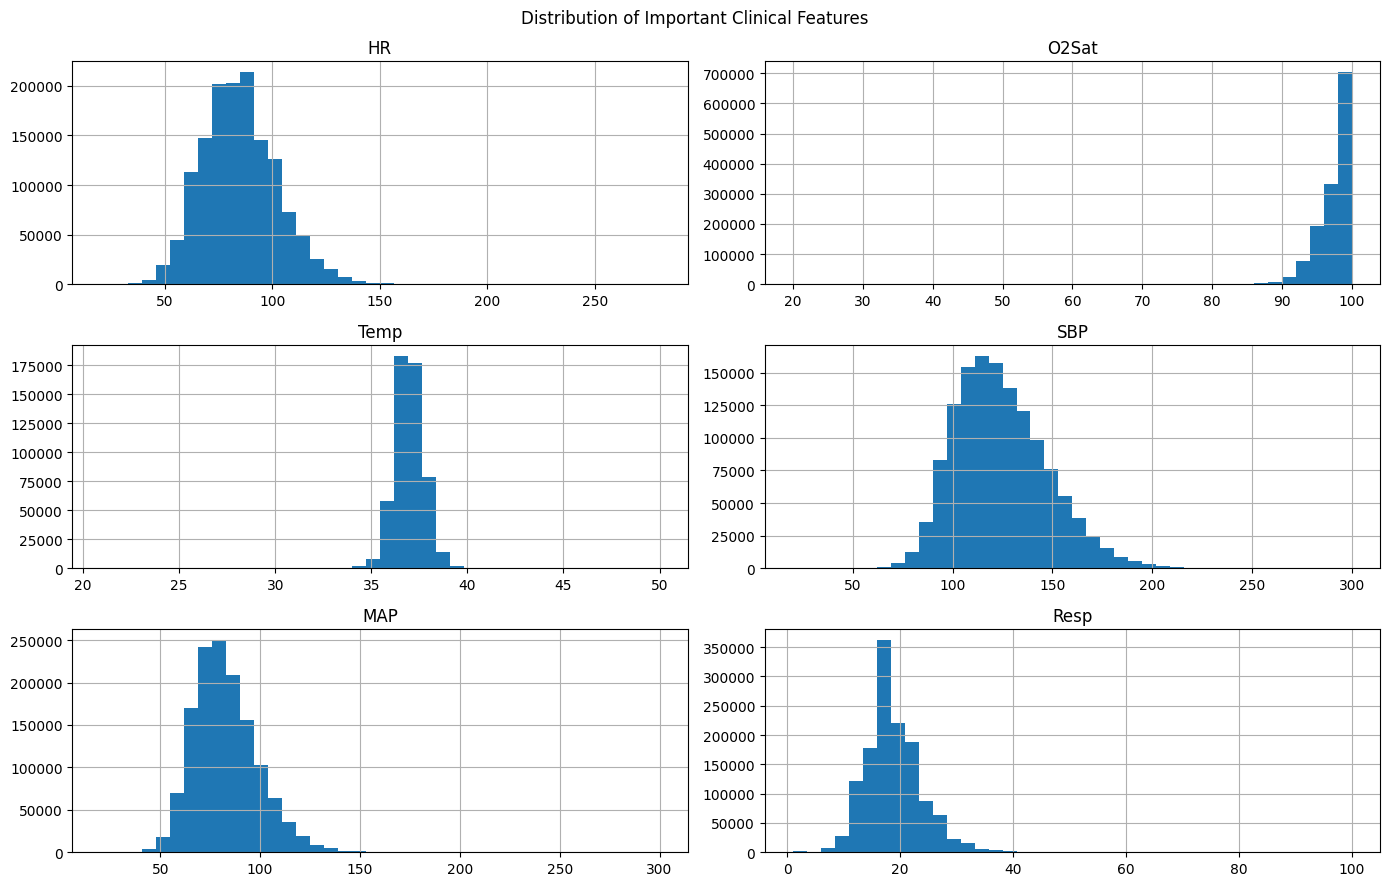

In [ ]:
clinical_features = [
    "HR", "O2Sat", "Temp",
    "SBP", "MAP", "Resp"
]

data[clinical_features].hist(
    figsize=(14, 9),
    bins=40
)

plt.suptitle("Distribution of Important Clinical Features")
plt.tight_layout()
plt.show()

In [ ]:
print(
    data.groupby("SepsisLabel")[clinical_features]
    .mean()
    .round(2)
)

                HR  O2Sat   Temp     SBP    MAP   Resp
SepsisLabel                                           
0            84.47  97.20  36.97  123.79  82.44  18.69
1            90.79  96.99  37.25  121.45  80.17  20.46


In [ ]:
os.makedirs("/content/sepsis_outputs", exist_ok=True)

missing_summary.to_csv(
    "/content/sepsis_outputs/missing_values_summary.csv"
)

patient_counts.to_csv(
    "/content/sepsis_outputs/patient_sepsis_distribution.csv"
)

print("EDA summary files saved successfully!")

EDA summary files saved successfully!


**Patient Level Labels**

In [ ]:
from sklearn.model_selection import train_test_split

patient_labels = (
    data.groupby("Patient_ID")["SepsisLabel"]
    .max()
    .reset_index()
)

print("Total patients:", len(patient_labels))

print("\nPatient-level distribution:")
print(patient_labels["SepsisLabel"].value_counts())

Total patients: 40336

Patient-level distribution:
SepsisLabel
0    37404
1     2932
Name: count, dtype: int64


In [ ]:
train_patients, temp_patients = train_test_split(
    patient_labels,
    test_size=0.30,
    stratify=patient_labels["SepsisLabel"],
    random_state=42
)

In [ ]:
val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    stratify=temp_patients["SepsisLabel"],
    random_state=42
)

In [ ]:
print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Testing patients:", len(test_patients))

print("\nTraining sepsis distribution:")
print(train_patients["SepsisLabel"].value_counts())

print("\nValidation sepsis distribution:")
print(val_patients["SepsisLabel"].value_counts())

print("\nTesting sepsis distribution:")
print(test_patients["SepsisLabel"].value_counts())

Training patients: 28235
Validation patients: 6050
Testing patients: 6051

Training sepsis distribution:
SepsisLabel
0    26183
1     2052
Name: count, dtype: int64

Validation sepsis distribution:
SepsisLabel
0    5610
1     440
Name: count, dtype: int64

Testing sepsis distribution:
SepsisLabel
0    5611
1     440
Name: count, dtype: int64


In [ ]:
# Extract patient IDs from each split
train_ids = train_patients["Patient_ID"].tolist()
val_ids = val_patients["Patient_ID"].tolist()
test_ids = test_patients["Patient_ID"].tolist()

# Assign all hourly records to their respective groups
train_data = data[data["Patient_ID"].isin(train_ids)].copy()

val_data = data[data["Patient_ID"].isin(val_ids)].copy()

test_data = data[data["Patient_ID"].isin(test_ids)].copy()

# Display dataset shapes
print("Training data shape:", train_data.shape)
print("Validation data shape:", val_data.shape)
print("Testing data shape:", test_data.shape)

Training data shape: (1086436, 42)
Validation data shape: (231472, 42)
Testing data shape: (234302, 42)


In [ ]:
print("Train and validation overlap:",
      len(set(train_ids) & set(val_ids)))

print("Train and test overlap:",
      len(set(train_ids) & set(test_ids)))

print("Validation and test overlap:",
      len(set(val_ids) & set(test_ids)))

Train and validation overlap: 0
Train and test overlap: 0
Validation and test overlap: 0


In [ ]:
# Sort records chronologically within each patient
train_data = train_data.sort_values(
    ["Patient_ID", "ICULOS"]
).copy()

val_data = val_data.sort_values(
    ["Patient_ID", "ICULOS"]
).copy()

test_data = test_data.sort_values(
    ["Patient_ID", "ICULOS"]
).copy()

# Columns that should not be model inputs
exclude_cols = ["Patient_ID", "SepsisLabel"]

feature_cols = [
    col for col in data.columns
    if col not in exclude_cols
]

print("Number of features:", len(feature_cols))
print(feature_cols)

Number of features: 40
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS']


In [ ]:
# Fill missing measurements using past observations only
train_data[feature_cols] = (
    train_data.groupby("Patient_ID")[feature_cols].ffill()
)

val_data[feature_cols] = (
    val_data.groupby("Patient_ID")[feature_cols].ffill()
)

test_data[feature_cols] = (
    test_data.groupby("Patient_ID")[feature_cols].ffill()
)

In [ ]:
# Add missingness indicators
missing_cols = [
    col for col in feature_cols
    if train_data[col].isnull().any()
]

for col in missing_cols:
    train_data[col + "_missing"] = train_data[col].isnull().astype(int)
    val_data[col + "_missing"] = val_data[col].isnull().astype(int)
    test_data[col + "_missing"] = test_data[col].isnull().astype(int)

# Calculate medians using training data only
medians = train_data[feature_cols].median()

# Apply the same training medians to all datasets
train_data[feature_cols] = train_data[feature_cols].fillna(medians)
val_data[feature_cols] = val_data[feature_cols].fillna(medians)
test_data[feature_cols] = test_data[feature_cols].fillna(medians)

print("Remaining missing values:")
print(train_data[feature_cols].isnull().sum().sum())
print(val_data[feature_cols].isnull().sum().sum())
print(test_data[feature_cols].isnull().sum().sum())

Remaining missing values:
0
0
0


In [ ]:
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# 1. Select features, including missingness indicators
model_features = feature_cols + [c + "_missing" for c in missing_cols]

X_train_full = train_data[model_features]
y_train_full = train_data["SepsisLabel"]

X_val = val_data[model_features]
y_val = val_data["SepsisLabel"]

# 2. Take a stratified sample for faster training
X_sample, _, y_sample, _ = train_test_split(
    X_train_full,
    y_train_full,
    train_size=300000,
    stratify=y_train_full,
    random_state=42
)

print("Training sample:", X_sample.shape)
print("Sepsis distribution:")
print(y_sample.value_counts())

# 3. Logistic Regression
scaler = StandardScaler()

X_sample_scaled = scaler.fit_transform(X_sample)
X_val_scaled = scaler.transform(X_val)

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=200,
    solver="lbfgs"
)

print("\nTraining Logistic Regression...")
lr_model.fit(X_sample_scaled, y_sample)

lr_predictions = lr_model.predict(X_val_scaled)
lr_probabilities = lr_model.predict_proba(X_val_scaled)[:, 1]

print("\nLOGISTIC REGRESSION RESULTS")
print(classification_report(y_val, lr_predictions))
print("PR-AUC:", average_precision_score(y_val, lr_probabilities))
print("ROC-AUC:", roc_auc_score(y_val, lr_probabilities))
print("Confusion Matrix:\n", confusion_matrix(y_val, lr_predictions))

# 4. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=20,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("\nTraining Random Forest...")
rf_model.fit(X_sample, y_sample)

rf_predictions = rf_model.predict(X_val)
rf_probabilities = rf_model.predict_proba(X_val)[:, 1]

print("\nRANDOM FOREST RESULTS")
print(classification_report(y_val, rf_predictions))
print("PR-AUC:", average_precision_score(y_val, rf_probabilities))
print("ROC-AUC:", roc_auc_score(y_val, rf_probabilities))
print("Confusion Matrix:\n", confusion_matrix(y_val, rf_predictions))

# 5. Save models and preprocessing objects
joblib.dump(lr_model, "logistic_regression.pkl")
joblib.dump(rf_model, "random_forest.pkl")
joblib.dump(scaler, "standard_scaler.pkl")
joblib.dump(model_features, "feature_columns.pkl")

print("\nModels and feature information saved successfully!")

Training sample: (300000, 77)
Sepsis distribution:
SepsisLabel
0    294599
1      5401
Name: count, dtype: int64

Training Logistic Regression...

LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

           0       0.99      0.76      0.86    227310
           1       0.05      0.67      0.09      4162

    accuracy                           0.76    231472
   macro avg       0.52      0.71      0.47    231472
weighted avg       0.98      0.76      0.84    231472

PR-AUC: 0.07263974295424219
ROC-AUC: 0.7813453403829183
Confusion Matrix:
 [[171979  55331]
 [  1368   2794]]

Training Random Forest...

RANDOM FOREST RESULTS
              precision    recall  f1-score   support

           0       0.99      0.96      0.97    227310
           1       0.10      0.24      0.15      4162

    accuracy                           0.95    231472
   macro avg       0.54      0.60      0.56    231472
weighted avg       0.97      0.95      0.96    231472

PR-AUC: 0.0

Generating SHAP values...
                    Feature  Mean_Absolute_SHAP
39                   ICULOS            0.070829
38              HospAdmTime            0.024891
2                      Temp            0.024097
50             FiO2_missing            0.021954
0                        HR            0.020215
62          Lactate_missing            0.018319
52            PaCO2_missing            0.015746
31                      WBC            0.012201
6                      Resp            0.011550
15                      BUN            0.011513
54              AST_missing            0.011118
51               pH_missing            0.010495
66  Bilirubin_total_missing            0.010231
19               Creatinine            0.010159
10                     FiO2            0.009659
4                       MAP            0.009650
64        Phosphate_missing            0.009389
33                Platelets            0.009358
3                       SBP            0.009244
34            

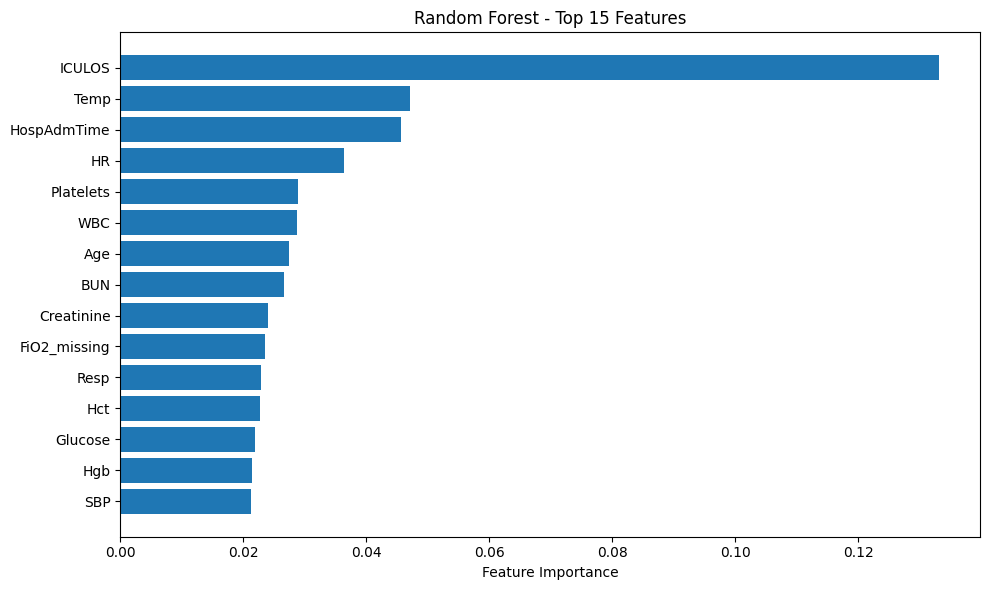

SHAP and feature importance files saved!


In [ ]:
!pip -q install shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select 500 validation records for faster SHAP calculation
X_shap = X_val.sample(
    n=min(500, len(X_val)),
    random_state=42
)

print("Generating SHAP values...")

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_positive = shap_values[1]
elif shap_values.ndim == 3:
    shap_positive = shap_values[:, :, 1]
else:
    shap_positive = shap_values

# Calculate mean absolute SHAP importance
shap_importance = pd.DataFrame({
    "Feature": model_features,
    "Mean_Absolute_SHAP": np.abs(shap_positive).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

print(shap_importance.head(20))

# Save SHAP output
shap_importance.to_csv("rf_shap_importance.csv", index=False)

np.savez_compressed(
    "rf_shap_values.npz",
    shap_values=shap_positive,
    feature_names=np.array(model_features),
    sample_indices=X_shap.index.to_numpy()
)

# Feature importance from Random Forest
rf_importance = pd.DataFrame({
    "Feature": model_features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

rf_importance.to_csv("rf_feature_importance.csv", index=False)

# Plot top 15 features
plt.figure(figsize=(10, 6))
plt.barh(
    rf_importance.head(15)["Feature"][::-1],
    rf_importance.head(15)["Importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.title("Random Forest - Top 15 Features")
plt.tight_layout()
plt.savefig("rf_feature_importance.png")
plt.show()

print("SHAP and feature importance files saved!")

In [ ]:
import joblib
import json
import os
import zipfile

# Save models and preprocessing information
joblib.dump(lr_model, "logistic_regression.pkl")
joblib.dump(rf_model, "random_forest.pkl")
joblib.dump(scaler, "standard_scaler.pkl")
joblib.dump(model_features, "feature_columns.pkl")
joblib.dump(medians, "training_medians.pkl")

# Save patient split IDs
joblib.dump({
    "train_ids": train_ids,
    "validation_ids": val_ids,
    "test_ids": test_ids
}, "patient_splits.pkl")

# Save validation predictions for comparison
validation_predictions = pd.DataFrame({
    "Actual": y_val,
    "LR_Probability": lr_probabilities,
    "RF_Probability": rf_probabilities
})

validation_predictions.to_csv(
    "validation_predictions.csv",
    index=False
)

# Package the deliverables
files_to_save = [
    "logistic_regression.pkl",
    "random_forest.pkl",
    "standard_scaler.pkl",
    "feature_columns.pkl",
    "training_medians.pkl",
    "patient_splits.pkl",
    "validation_predictions.csv",
    "rf_feature_importance.csv",
    "rf_shap_importance.csv",
    "rf_shap_values.npz",
    "rf_feature_importance.png"
]

with zipfile.ZipFile(
    "SEPSIS_AI_Person1_Deliverables.zip",
    "w"
) as zipf:

    for file in files_to_save:
        if os.path.exists(file):
            zipf.write(file)

print("Person 1 deliverables packaged!")

Person 1 deliverables packaged!


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sepsis_data', 'standard_scaler.pkl', 'rf_feature_importance.csv', 'logistic_regression.pkl', 'sepsis_outputs', 'validation_predictions.csv', 'training_medians.pkl', 'rf_shap_values.npz', 'SEPSIS_AI_Person1_Deliverables.zip', 'random_forest.pkl', 'rf_shap_importance.csv', 'feature_columns.pkl', 'rf_feature_importance.png', 'patient_splits.pkl', 'sample_data']


In [ ]:
from google.colab import files

files.download("logistic_regression.pkl")
files.download("random_forest.pkl")
files.download("standard_scaler.pkl")
files.download("feature_columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("SEPSIS_AI_Person1_Deliverables.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>